# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [ ]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib scipy
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

In [3]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.15.0+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [4]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 2
Estado siguiente: [ 0.004  1.426  0.217  0.344 -0.006 -0.067  0.     0.   ]
Recompensa: -2.497
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [5]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [6]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [7]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)                                        

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [8]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [11]:
# Implementación del agente DQN
class RedQ(nn.Module):
    """Red totalmente conectada.La entrada es el vector de estado continuo (8 componentes).
    """

    def __init__(self, dim_entrada, dim_salida, ocultas=(128, 128)):
        super().__init__()
        capas = []
        anterior = dim_entrada
        for oculta in ocultas:
            capas.append(nn.Linear(anterior, oculta))
            capas.append(nn.ReLU())
            anterior = oculta
        capas.append(nn.Linear(anterior, dim_salida))
        self.capas = nn.Sequential(*capas)

    def forward(self, x):
        return self.capas(x)


class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Los interruptores `usar_replay`, `usar_red_objetivo` y `decaer_epsilon`
    (todos en `True` por omisión) permiten apagar cada componente de DQN por
    separado para el estudio de ablación de la sección 11, sin duplicar la clase.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 ocultas=(128, 128), lr=5e-4, gamma=0.99,
                 epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01,
                 memoria_max=100_000, batch_size=64, pasos_sync_objetivo=1000,
                 usar_replay=True, usar_red_objetivo=True, decaer_epsilon=True):
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)

        # El estado es un vector continuo (Box(8,)): usamos shape[0], no `.n`.
        self.dim_estado = estado_space.shape[0]
        self.n_acciones = accion_space.n

        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.batch_size = batch_size
        self.pasos_sync_objetivo = pasos_sync_objetivo
        self.pasos_dados = 0

        # Interruptores para el estudio de ablación (sección 11)
        self.usar_replay = usar_replay
        self.usar_red_objetivo = usar_red_objetivo
        self.decaer_epsilon = decaer_epsilon

        # Red principal y red objetivo: una copia congelada que se sincroniza
        # cada `pasos_sync_objetivo` pasos para estabilizar el target de Bellman.
        self.red_q = RedQ(self.dim_estado, self.n_acciones, ocultas)
        self.red_objetivo = RedQ(self.dim_estado, self.n_acciones, ocultas)
        self.red_objetivo.load_state_dict(self.red_q.state_dict())
        self.red_objetivo.eval()

        self.criterio = nn.SmoothL1Loss()  # Huber: más robusto que MSE a recompensas extremas
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

        # Sin replay (ablación) el buffer se limita a un batch: se entrena casi
        # en línea, sin la diversidad de muestras de un replay real.
        tamano_memoria = memoria_max if usar_replay else batch_size
        self.memoria = deque(maxlen=tamano_memoria)

    def elegir_accion(self, estado, explorar=True):
        """Elige acción con política epsilon-greedy; acción greedy si `explorar=False`."""
        if explorar and random.random() < self.epsilon:
            return random.randrange(self.n_acciones)

        estado_t = torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            q_valores = self.red_q(estado_t)
        return int(torch.argmax(q_valores).item())

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Guarda la experiencia en memoria y da un paso de descenso de gradiente."""
        self.memoria.append((estado, accion, recompensa, siguiente_estado, terminado))
        self.pasos_dados += 1

        if self.usar_red_objetivo:
            if self.pasos_dados % self.pasos_sync_objetivo == 0:
                self.red_objetivo.load_state_dict(self.red_q.state_dict())
        else:
            # Sin red objetivo: el target se calcula con la misma red que se
            # está entrenando, así que la copia se sincroniza en cada paso.
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

        if len(self.memoria) < self.batch_size:
            return  # warm-up: todavía no hay suficientes transiciones

        batch = random.sample(self.memoria, self.batch_size)
        estados, acciones, recompensas, siguientes, terminados = zip(*batch)

        estados_t = torch.as_tensor(np.array(estados), dtype=torch.float32)
        acciones_t = torch.as_tensor(acciones, dtype=torch.long).unsqueeze(1)
        recompensas_t = torch.as_tensor(recompensas, dtype=torch.float32).unsqueeze(1)
        siguientes_t = torch.as_tensor(np.array(siguientes), dtype=torch.float32)
        terminados_t = torch.as_tensor(terminados, dtype=torch.float32).unsqueeze(1)

        # Q-valor de la acción efectivamente tomada, según la red principal
        q_valores = self.red_q(estados_t).gather(1, acciones_t)

        # Target TD: r + gamma * max_a' Q(s', a') * (1 - terminado), sin gradiente
        with torch.no_grad():
            q_siguiente_max = self.red_objetivo(siguientes_t).max(1, keepdim=True)[0]
            objetivo = recompensas_t + (1 - terminados_t) * self.gamma * q_siguiente_max

        perdida = self.criterio(q_valores, objetivo)

        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), max_norm=10.0)
        self.optimizador.step()

    def fin_episodio(self):
        """Decae epsilon al terminar cada episodio (si `decaer_epsilon=True`)."""
        if self.decaer_epsilon:
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


## 6.1. Calibración de hiperparámetros

Antes del entrenamiento final de la sección 7 conviene elegir los hiperparámetros
con una búsqueda chica: se entrena cada combinación candidata con **pocos
episodios** (una fracción del entrenamiento final) y **varias semillas** (para no
confundir "esta configuración es buena" con "esta corrida tuvo suerte"), se evalúa
sin exploración sobre semillas fijas, y se compara la recompensa promedio de
evaluación.

**Qué fija una semilla acá.** Los generadores pseudoaleatorios de `random`, NumPy y
PyTorch (exploración ε-greedy, muestreo del replay buffer e inicialización de los
pesos de la red) y los estados iniciales que sortea Gymnasium al resetear el
entorno. Con la misma semilla la corrida es reproducible; con otra semilla la
misma configuración de hiperparámetros puede dar resultados bastante distintos,
por eso se promedia sobre varias en vez de confiar en una sola corrida (el mismo
espíritu que promediar folds en validación cruzada, pero acá la fuente de
varianza es el entrenamiento en sí, no la partición de un dataset).

Por costo (cada entrenamiento de LunarLander tarda bastante más que uno de
FrozenLake) no se hace un grid exhaustivo: se arma una lista chica de candidatos
razonables, variando de a uno o dos hiperparámetros por vez, y se compara.


In [16]:
# Búsqueda de hiperparámetros (ver sección 6.1): entrenamiento corto + varias
# semillas por candidato, para elegir la configuración que usa el entrenamiento
# final de la sección 7.
import time

candidatos_dqn = [
    dict(lr=1e-4, ocultas=(128, 128), epsilon_decay=0.995, gamma=0.99),
    dict(lr=5e-4, ocultas=(128, 128), epsilon_decay=0.995, gamma=0.99),
    dict(lr=1e-3, ocultas=(128, 128), epsilon_decay=0.995, gamma=0.99),
    dict(lr=5e-4, ocultas=(128,),     epsilon_decay=0.995, gamma=0.99),
    dict(lr=5e-4, ocultas=(128, 128), epsilon_decay=0.99,  gamma=0.99),
    dict(lr=5e-4, ocultas=(128, 128), epsilon_decay=0.995, gamma=0.995),
]

semillas_busqueda = [0, 1, 2]      # varias semillas por candidato: controla la varianza del entrenamiento
episodios_busqueda = 300           # bastante menos que los 1200 del entrenamiento final, solo para comparar
episodios_eval_busqueda = 50

resultados_busqueda = []
t_inicio_busqueda = time.time()

for config in candidatos_dqn:
    puntajes = []
    for s in semillas_busqueda:
        env = gym.make('LunarLander-v3')
        agente = AgenteDQN(env.observation_space, env.action_space, semilla=s, **config)
        entrenar_agente(agente, env, num_episodios=episodios_busqueda, semilla=s, verbose=False)
        r = evaluar_agente(agente, env, num_episodios=episodios_eval_busqueda, semilla=10_000)
        puntajes.append(r['recompensa_promedio'])
        env.close()
    media, desv = float(np.mean(puntajes)), float(np.std(puntajes))
    resultados_busqueda.append({**config, 'recompensa_media': media, 'recompensa_desv': desv})
    print(f"{config} -> recompensa media {media:7.1f} +/- {desv:5.1f}  "
          f"(semillas: {[round(p, 1) for p in puntajes]})", flush=True)

print(f"\nTiempo total de búsqueda: {time.time() - t_inicio_busqueda:.0f}s")

# Tabla ordenada de mejor a peor
resultados_busqueda.sort(key=lambda r: r['recompensa_media'], reverse=True)
print(f"\n{'lr':>8} {'ocultas':>14} {'epsilon_decay':>14} {'gamma':>7} {'recompensa':>18}")
for r in resultados_busqueda:
    print(f"{r['lr']:>8} {str(r['ocultas']):>14} {r['epsilon_decay']:>14} {r['gamma']:>7} "
          f"{r['recompensa_media']:9.1f} +/- {r['recompensa_desv']:5.1f}")

mejor_config = resultados_busqueda[0]
mejores_hiperparametros = {k: v for k, v in mejor_config.items()
                           if k not in ('recompensa_media', 'recompensa_desv')}

print(f"\nMejor configuración encontrada: {mejores_hiperparametros}")
print(f"Recompensa media de evaluación: {mejor_config['recompensa_media']:.1f} +/- {mejor_config['recompensa_desv']:.1f}")


Tiempo total de entrenamiento: 533s
Tiempo total de entrenamiento: 548s
Tiempo total de entrenamiento: 498s
{'lr': 0.0001, 'ocultas': (128, 128), 'epsilon_decay': 0.995, 'gamma': 0.99} -> recompensa media   108.5 +/-  42.2  (semillas: [158.6, 111.4, 55.4])
Tiempo total de entrenamiento: 456s
Tiempo total de entrenamiento: 412s
Tiempo total de entrenamiento: 381s
{'lr': 0.0005, 'ocultas': (128, 128), 'epsilon_decay': 0.995, 'gamma': 0.99} -> recompensa media   236.8 +/-  23.6  (semillas: [213.2, 269.0, 228.1])
Tiempo total de entrenamiento: 370s
Tiempo total de entrenamiento: 283s
Tiempo total de entrenamiento: 357s
{'lr': 0.001, 'ocultas': (128, 128), 'epsilon_decay': 0.995, 'gamma': 0.99} -> recompensa media   212.7 +/-  11.7  (semillas: [222.8, 196.3, 218.9])
Tiempo total de entrenamiento: 338s
Tiempo total de entrenamiento: 331s
Tiempo total de entrenamiento: 409s
{'lr': 0.0005, 'ocultas': (128,), 'epsilon_decay': 0.995, 'gamma': 0.99} -> recompensa media    55.8 +/-  31.8  (semilla

## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [12]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

# Si no se corrió la celda de calibración (6.1), se usan valores por defecto razonables.
hiperparametros_dqn = mejores_hiperparametros if 'mejores_hiperparametros' in globals() else dict(
    lr=5e-4, ocultas=(128, 128), epsilon_decay=0.995, gamma=0.99)
agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA, **hiperparametros_dqn)

# print("\nEntrenando el agente DQN en LunarLander-v3...")
# recompensas_episodios, longitudes_episodios = entrenar_agente(
#     agente_dqn, env,
#     num_episodios=1200,
#     max_pasos=1000,
#     umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
#     semilla=SEMILLA,
#     verbose=True,
# )

env.close()

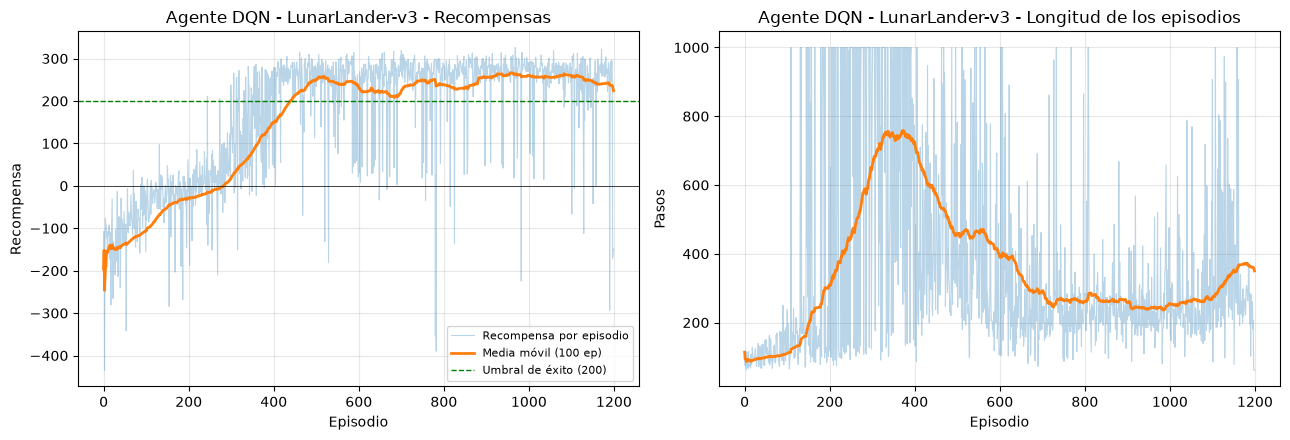

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 224.06
Tasa de éxito (R ≥ 200): 83.0%
Epsilon final: 0.010


In [18]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [13]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
# torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con 
agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt'))


<All keys matched successfully>

## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [20]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 74.5%
Recompensa promedio: 226.01
Recompensa mediana:  244.39
Desviación estándar: 68.83
Total de éxitos: 149 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


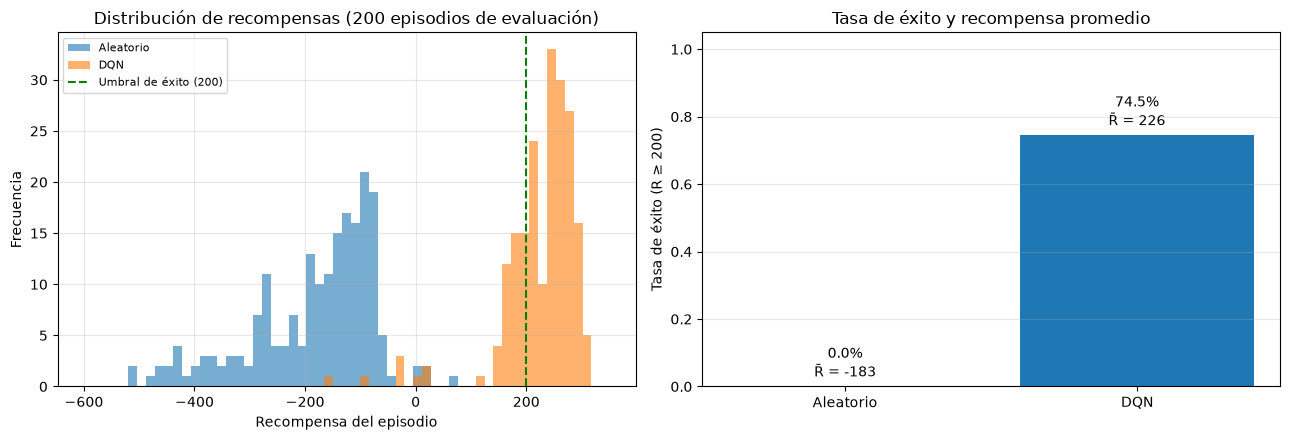

Tasa de éxito DQN:       74.5%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 409.2 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  74.5%
  R ≥  150:  94.0%
  R ≥  100:  96.0%
  R ≥    0:  97.5%
  Episodios que se estrellan (R < -50): 1.0%


In [21]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  251 pasos, recompensa   280.2
  semilla 27739:  549 pasos, recompensa   216.7
  semilla 26545:  364 pasos, recompensa   227.3
  semilla 24388:  250 pasos, recompensa   276.8
  semilla 24330:  543 pasos, recompensa   242.3
  semilla 28585:  589 pasos, recompensa   231.7
  semilla 20859:  583 pasos, recompensa   171.1
  semilla 26973:  270 pasos, recompensa   303.9
  semilla 22014:  701 pasos, recompensa   185.3
  semilla 20941:  564 pasos, recompensa   191.7

7/10 episodios exitosos, recompensa media 232.7 → aterrizaje_dqn.gif


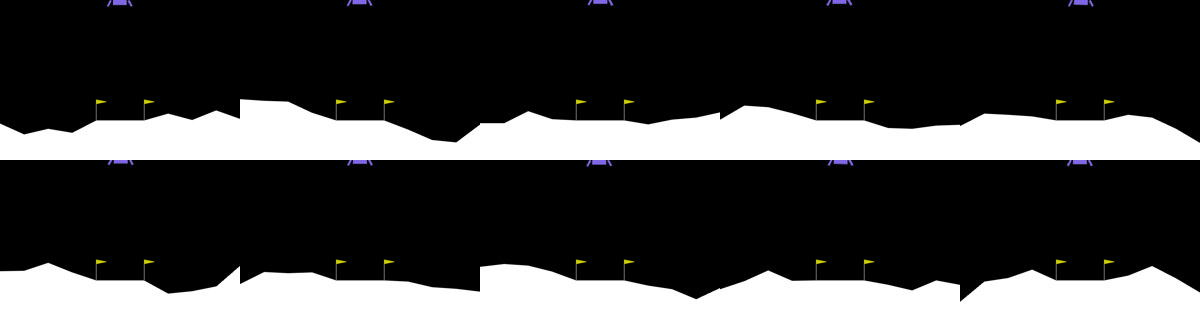

In [22]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


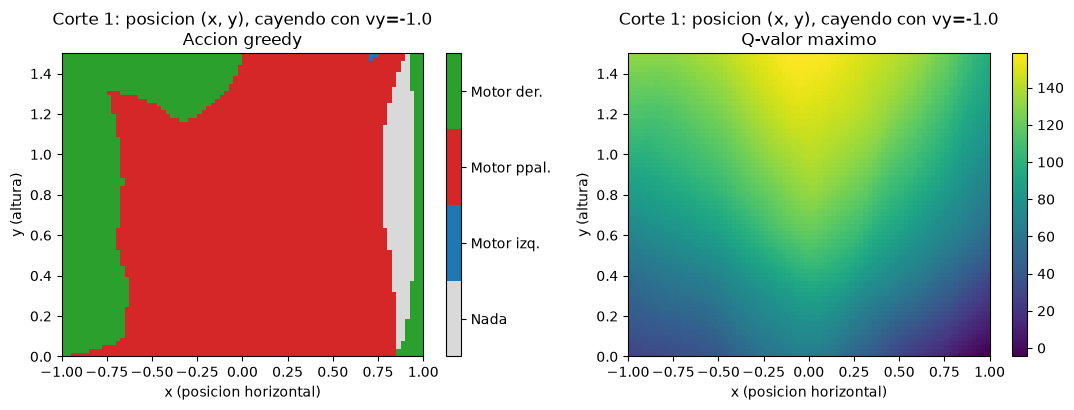

Corte 1 - distribucion de acciones: {'Nada': 0.06046875, 'Motor izq.': 0.00046875, 'Motor ppal.': 0.6925, 'Motor der.': 0.2465625}
  franja central |x|<=0.2: {'Nada': 0.0, 'Motor izq.': 0.0, 'Motor ppal.': 0.93984375, 'Motor der.': 0.06015625}
  costados |x|>0.2:        {'Nada': 0.0755859375, 'Motor izq.': 0.0005859375, 'Motor ppal.': 0.6306640625, 'Motor der.': 0.2931640625}


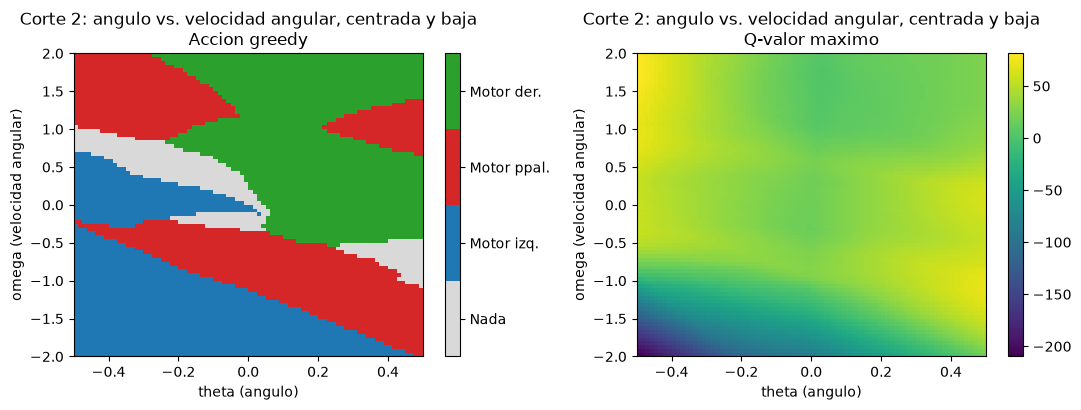

Corte 2 - distribucion de acciones: {'Nada': 0.086875, 'Motor izq.': 0.2834375, 'Motor ppal.': 0.30640625, 'Motor der.': 0.32328125}
  theta < 0: {'Nada': 0.1225, 'Motor izq.': 0.4584375, 'Motor ppal.': 0.31125, 'Motor der.': 0.1078125}
  theta > 0: {'Nada': 0.05125, 'Motor izq.': 0.1084375, 'Motor ppal.': 0.3015625, 'Motor der.': 0.53875}


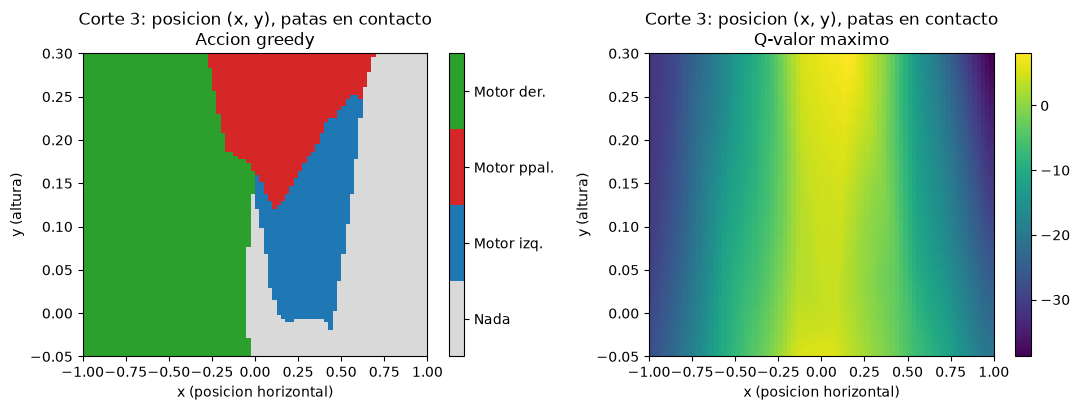

Corte 3 - distribucion de acciones: {'Nada': 0.2753125, 'Motor izq.': 0.1309375, 'Motor ppal.': 0.14265625, 'Motor der.': 0.45109375}

Q-valor maximo (media): corte1=95.2  corte2=17.7  corte3=-10.4


In [23]:
# TODO 2: cortes de la politica
#
# Plan de analisis (3 enfoques, ver analisis_de_politica.md para el detalle):
#   1) Posicion (x, y) con la nave cayendo nivelada (vy=-1.0, theta=omega=0,
#      sin contacto): valida si el motor principal domina cerca del centro y
#      los laterales corrigen a los costados.
#   2) Angulo (theta) vs. velocidad angular (omega), cerca del suelo y
#      centrada: valida si la politica corrige la inclinacion de forma
#      simetrica (un motor lateral para theta>0 y el otro para theta<0).
#   3) La misma region de posicion del corte 1 pero con ambas patas en
#      contacto: valida si la politica se vuelve mas pasiva al aterrizar.
#
# Indices del vector de estado: 0=x, 1=y, 2=vx, 3=vy, 4=theta, 5=omega,
# 6=contacto pata izq., 7=contacto pata der.

from matplotlib.colors import ListedColormap

NOMBRES_ACCION = ['Nada', 'Motor izq.', 'Motor ppal.', 'Motor der.']
CMAP_ACCION = ListedColormap(['#d9d9d9', '#1f77b4', '#d62728', '#2ca02c'])


def cortar_politica(agente, fijos, idx1, rango1, idx2, rango2):
    """Barre dos dimensiones del estado (idx1, idx2) dejando el resto fijo
    segun `fijos` (dict indice->valor). Devuelve la accion greedy y el
    Q-valor maximo del agente en cada punto de la grilla (rango2 x rango1)."""
    mapa_accion = np.zeros((len(rango2), len(rango1)), dtype=int)
    mapa_qmax = np.zeros((len(rango2), len(rango1)), dtype=float)
    for i, v2 in enumerate(rango2):
        for j, v1 in enumerate(rango1):
            estado = np.zeros(8, dtype=np.float32)
            for k, val in fijos.items():
                estado[k] = val
            estado[idx1], estado[idx2] = v1, v2
            mapa_accion[i, j] = agente.elegir_accion(estado, explorar=False)
            estado_t = torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)
            with torch.no_grad():
                mapa_qmax[i, j] = agente.red_q(estado_t).max().item()
    return mapa_accion, mapa_qmax


def graficar_corte(mapa_accion, mapa_qmax, extent, titulo, xlabel, ylabel):
    """Grafica lado a lado la accion greedy (mapa categorico) y el Q-valor
    maximo (mapa de calor) de un corte de la politica."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    im1 = ax1.imshow(mapa_accion, origin='lower', extent=extent, aspect='auto',
                      cmap=CMAP_ACCION, vmin=-0.5, vmax=3.5)
    ax1.set_title(f'{titulo}\nAccion greedy')
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel)
    cbar = fig.colorbar(im1, ax=ax1, ticks=[0, 1, 2, 3])
    cbar.ax.set_yticklabels(NOMBRES_ACCION)

    im2 = ax2.imshow(mapa_qmax, origin='lower', extent=extent, aspect='auto', cmap='viridis')
    ax2.set_title(f'{titulo}\nQ-valor maximo')
    ax2.set_xlabel(xlabel)
    ax2.set_ylabel(ylabel)
    fig.colorbar(im2, ax=ax2)
    plt.tight_layout()
    plt.show()


def resumen_distribucion(mapa_accion):
    """Fraccion de celdas de la grilla en que domina cada accion."""
    total = mapa_accion.size
    return {NOMBRES_ACCION[a]: float((mapa_accion == a).sum()) / total for a in range(4)}


# --- Corte 1: posicion (x, y), nave cayendo nivelada, sin contacto -------
rango_x = np.linspace(-1.0, 1.0, 80)
rango_y = np.linspace(0.0, 1.5, 80)
fijos_1 = {2: 0.0, 3: -1.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0}
mapa_a1, mapa_q1 = cortar_politica(agente_dqn, fijos_1, 0, rango_x, 1, rango_y)
graficar_corte(mapa_a1, mapa_q1, [-1, 1, 0, 1.5],
               'Corte 1: posicion (x, y), cayendo con vy=-1.0',
               'x (posicion horizontal)', 'y (altura)')
print('Corte 1 - distribucion de acciones:', resumen_distribucion(mapa_a1))
centro = np.abs(rango_x) <= 0.2
print('  franja central |x|<=0.2:', resumen_distribucion(mapa_a1[:, centro]))
print('  costados |x|>0.2:       ', resumen_distribucion(mapa_a1[:, ~centro]))

# --- Corte 2: angulo (theta) vs. velocidad angular (omega), cerca del suelo
rango_theta = np.linspace(-0.5, 0.5, 80)
rango_omega = np.linspace(-2.0, 2.0, 80)
fijos_2 = {0: 0.0, 1: 0.3, 2: 0.0, 3: 0.0, 6: 0.0, 7: 0.0}
mapa_a2, mapa_q2 = cortar_politica(agente_dqn, fijos_2, 4, rango_theta, 5, rango_omega)
graficar_corte(mapa_a2, mapa_q2, [-0.5, 0.5, -2.0, 2.0],
               'Corte 2: angulo vs. velocidad angular, centrada y baja',
               'theta (angulo)', 'omega (velocidad angular)')
print('Corte 2 - distribucion de acciones:', resumen_distribucion(mapa_a2))
mitad = len(rango_theta) // 2
print('  theta < 0:', resumen_distribucion(mapa_a2[:, :mitad]))
print('  theta > 0:', resumen_distribucion(mapa_a2[:, mitad:]))

# --- Corte 3: misma posicion del corte 1, pero con ambas patas en contacto
rango_y_aterrizado = np.linspace(-0.05, 0.3, 80)
fijos_3 = {2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 1.0, 7: 1.0}
mapa_a3, mapa_q3 = cortar_politica(agente_dqn, fijos_3, 0, rango_x, 1, rango_y_aterrizado)
graficar_corte(mapa_a3, mapa_q3, [-1, 1, -0.05, 0.3],
               'Corte 3: posicion (x, y), patas en contacto',
               'x (posicion horizontal)', 'y (altura)')
print('Corte 3 - distribucion de acciones:', resumen_distribucion(mapa_a3))

print(f'\nQ-valor maximo (media): corte1={mapa_q1.mean():.1f}  '
      f'corte2={mapa_q2.mean():.1f}  corte3={mapa_q3.mean():.1f}')



## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

**Consigna**: comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


Se compara el DQN completo con tres variantes, quitando un componente por vez:

* `sin_replay` (`usar_replay=False`): el buffer queda del tamaño de un batch.
* `sin_red_objetivo` (`usar_red_objetivo=False`): el target se calcula con la misma red que se entrena.
* `epsilon_fijo` (`decaer_epsilon=False`, `epsilon=0.1`): ε constante durante todo el entrenamiento. El valor 0.1 es una elección propia, no se calibró.

Cada variante se entrena con 8 semillas y se evalúa con 100 episodios sin exploración, con las mismas semillas de evaluación. Se compara cada variante contra el DQN completo con un test estadístico de Mann-Whitney U bilateral.

Son 32 entrenamientos en total, así que el costo se planifica de este modo:

* Se usan 800 episodios por corrida, menos que los 1200 del entrenamiento principal.
* Los resultados de cada variante se guardan en `ablacion_<variante>.json` después de cada semilla. Si el archivo existe y corresponde a la misma configuración (episodios y semillas), se reutiliza y no se reentrena; si se cortó a mitad, se retoma desde la última semilla guardada. Para repetir el estudio desde cero hay que borrar esos archivos.
* El análisis posterior solo usa lo guardado, por lo que se puede repetir sin reentrenar.

In [21]:
import json
import os

variantes = {
    "completo": dict(),
    "sin_replay": dict(usar_replay=False),
    "sin_red_objetivo": dict(usar_red_objetivo=False),
    "epsilon_fijo": dict(decaer_epsilon=False, epsilon=0.1),
}

semillas = [100, 101, 102, 103, 104, 105, 106, 107]   # distintas de las de la calibración (0, 1, 2)
episodios_ablacion = 800     # presupuesto de cómputo: menos que los 1200 del entrenamiento principal

resultados = {}      # recompensa de evaluación por semilla, para cada variante
curvas = {}          # recompensas de entrenamiento, para graficar el aprendizaje

for nombre, overrides in variantes.items():
    archivo = f"ablacion_{nombre}.json"
    resultados[nombre] = []
    curvas[nombre] = []

    # Si ya hay resultados guardados de la misma configuración, se reutilizan
    if os.path.exists(archivo):
        with open(archivo) as f:
            guardado = json.load(f)
        if guardado["episodios"] == episodios_ablacion and guardado["semillas"] == semillas:
            resultados[nombre] = guardado["resultados"]
            curvas[nombre] = guardado["curvas"]

    # Se entrenan solo las semillas que faltan, una después de otra
    for s in semillas[len(resultados[nombre]):]:
        env = gym.make('LunarLander-v3')
        agente = AgenteDQN(env.observation_space, env.action_space, semilla=s,
                           **hiperparametros_dqn, **overrides)
        recompensas_train, _ = entrenar_agente(agente, env, num_episodios=episodios_ablacion,
                                               semilla=s, verbose=False)
        r = evaluar_agente(agente, env, num_episodios=100, semilla=20_000)
        env.close()
        resultados[nombre].append(r['recompensa_promedio'])
        curvas[nombre].append(recompensas_train)

        # Se guarda después de cada semilla, así no se pierde lo ya entrenado
        with open(archivo, 'w') as f:
            json.dump({"episodios": episodios_ablacion, "semillas": semillas,
                       "resultados": resultados[nombre], "curvas": curvas[nombre]}, f)
        print(f"{nombre} | semilla {s}: recompensa de evaluación {r['recompensa_promedio']:.1f}", flush=True)

    print(f"{nombre}: recompensa de evaluación por semilla {np.round(resultados[nombre], 1)}")


completo: recompensa de evaluación por semilla [153.3 113.3 255.4 256.3 256.5 255.4 236.1 269.8]
sin_replay: recompensa de evaluación por semilla [ -24.  -133.5 -123.6 -190.  -221.4  -53.2 -244.4 -122.9]
sin_red_objetivo: recompensa de evaluación por semilla [ 207.6    4.   100.4 -544.4  190.5  230.1   18.1  171.7]
epsilon_fijo: recompensa de evaluación por semilla [257.8 269.1 205.1 210.  108.  -33.3 202.9 249.5]


In [22]:
# Comparación de cada variante contra el DQN completo (Mann-Whitney U, bilateral)
from scipy.stats import mannwhitneyu

base = resultados["completo"]
print(f"completo: media={np.mean(base):.1f} ± {np.std(base, ddof=1):.1f}  mediana={np.median(base):.1f}  "
      f"semillas con R ≥ 200: {(np.array(base) >= UMBRAL_EXITO).sum()}/{len(base)}")

for nombre, valores in resultados.items():
    if nombre == "completo":
        continue
    estadistico, p_valor = mannwhitneyu(base, valores, alternative='two-sided')
    print(f"{nombre}: media={np.mean(valores):.1f} ± {np.std(valores, ddof=1):.1f}  mediana={np.median(valores):.1f}  "
          f"semillas con R ≥ 200: {(np.array(valores) >= UMBRAL_EXITO).sum()}/{len(valores)}  "
          f"p-valor vs. completo={p_valor:.4f}")


completo: media=224.5 ± 58.0  mediana=255.4  semillas con R ≥ 200: 6/8
sin_replay: media=-139.1 ± 77.1  mediana=-128.5  semillas con R ≥ 200: 0/8  p-valor vs. completo=0.0002
sin_red_objetivo: media=47.2 ± 253.8  mediana=136.1  semillas con R ≥ 200: 2/8  p-valor vs. completo=0.0104
epsilon_fijo: media=183.7 ± 101.0  mediana=207.6  semillas con R ≥ 200: 6/8  p-valor vs. completo=0.3823


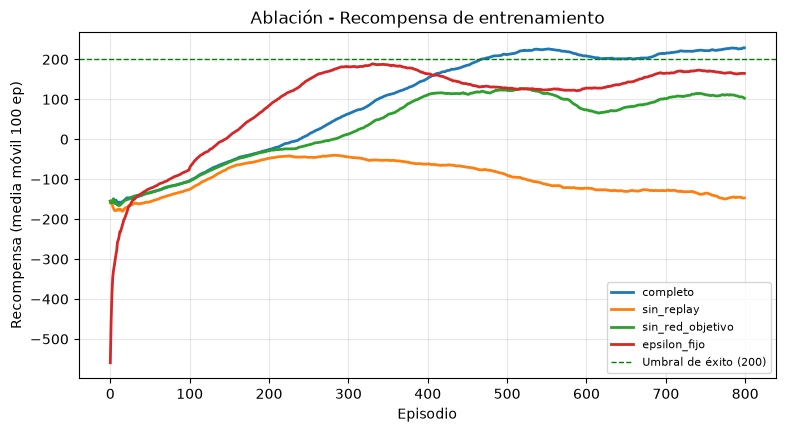

In [23]:
# Curvas de aprendizaje: media móvil de 100 episodios, promediada entre semillas
plt.figure(figsize=(9, 4.5))
for nombre, lista_curvas in curvas.items():
    suavizadas = [media_movil(c, 100) for c in lista_curvas]
    plt.plot(np.mean(suavizadas, axis=0), linewidth=2, label=nombre)
plt.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
plt.title("Ablación - Recompensa de entrenamiento")
plt.xlabel("Episodio")
plt.ylabel("Recompensa (media móvil 100 ep)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.show()
